<a href="https://colab.research.google.com/github/Sasha3424/23145/blob/main/26_27_grsu_ml_ind_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Индивидуальная практическая работа 4\. Базовая работа в PyTorch

1. Сделайте копию тетрадки.
2. Заполните тетрадку.

#Задание 1. Классифицируйте точки

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import sklearn
from sklearn.datasets import make_blobs
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap

In [11]:
# use GPU if available
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
device

device(type='cpu')

In [12]:
X, y = make_blobs(n_samples=400,
                  cluster_std=[1.0, 1.5, 0.5],
                  random_state=17)

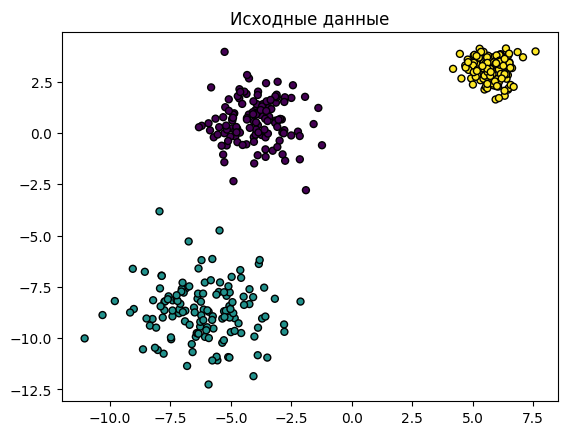

/tmp/ipykernel_566/2394694045.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
/tmp/ipykernel_566/2394694045.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_tensor = torch.tensor(y, dtype=torch.long).to(device)


In [20]:
# Визуализация исходных данных (необязательно, но полезно)
plt.scatter(X[:, 0], X[:, 1], marker='o', c=y, s=25, edgecolor='k')
plt.title("Исходные данные")
plt.show()

# 3. Преобразование numpy массивов в тензоры PyTorch
X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
y_tensor = torch.tensor(y, dtype=torch.long).to(device)


Классифицируйте данные с помощью нейронной сети.

In [21]:
model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
).to(device)

In [22]:
# Функция потерь и оптимизатор
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9)

In [26]:
# 3. Обучение
epochs = 1000
for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = model(X_tensor)
    loss = criterion(outputs, y_tensor)
    loss.backward()
    optimizer.step()

print(f"Финальная ошибка (Loss): {loss.item():.4f}")

Финальная ошибка (Loss): 0.0002


Визуализируйте результаты

/tmp/ipykernel_566/1231305471.py:7: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
/tmp/ipykernel_566/1231305471.py:8: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  np.arange(y_min, y_max, h))


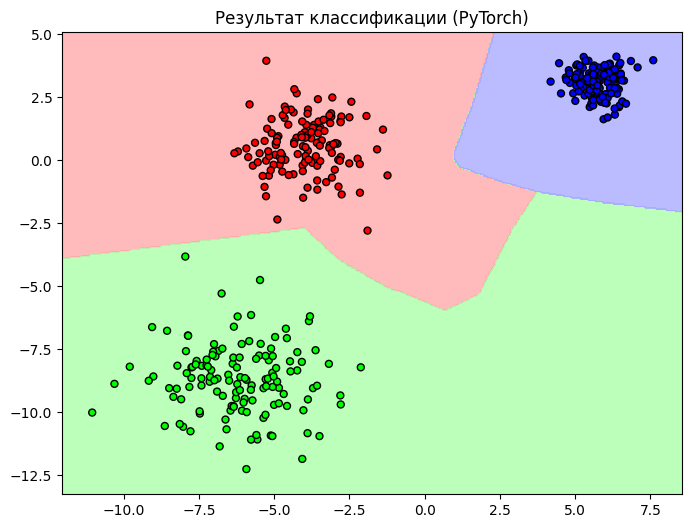

In [27]:
# 4. Визуализация результатов (границы решений)
# Создаем сетку
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
h = 0.05  # шаг сетки

xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

# Делаем предсказания для каждой точки сетки
grid_points = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32).to(device)

with torch.no_grad():
    Z = model(grid_points)
    # Берем класс с максимальной вероятностью
    _, Z_pred = torch.max(Z, 1)
    Z_pred = Z_pred.cpu().numpy().reshape(xx.shape)

# Рисуем контуры
plt.figure(figsize=(8, 6))
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

plt.contourf(xx, yy, Z_pred, cmap=cmap_light, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold, edgecolor='k', s=25)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.title("Результат классификации (PyTorch)")
plt.show()

# Задача 2. Классифицируте классы

In [28]:
import sklearn.datasets
wine = sklearn.datasets.load_wine()
wine.data.shape

(178, 13)

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    wine.data[:, :2],   # возьмем только 2 первых предиктора Alcohol, Malic acid (чтоб потом нарисовать)
    wine.target,
    test_size=0.3,
    shuffle=True)

In [31]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# Проверка устройства
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Работаем на: {device}")

Работаем на: cpu


## Визуализируйте результаты 1

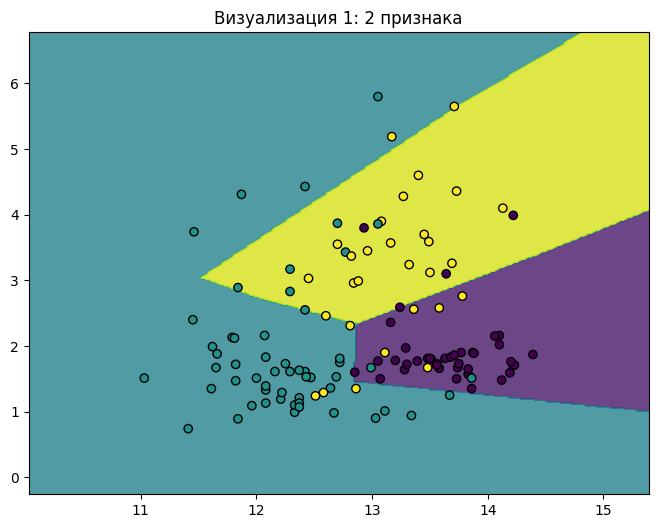

In [32]:
# Перевод данных (2 признака) в тензоры
X_train_t = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train, dtype=torch.long).to(device)

# Создание и обучение модели
model_2d = nn.Sequential(
    nn.Linear(2, 32),
    nn.ReLU(),
    nn.Linear(32, 3)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2d.parameters(), lr=0.01)

for epoch in range(500):
    optimizer.zero_grad()
    outputs = model_2d(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

# Визуализация (meshgrid и contourf)
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
h = 0.02
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32).to(device)
with torch.no_grad():
    Z = model_2d(grid)
    _, Z_pred = torch.max(Z, 1)
    Z_pred = Z_pred.cpu().numpy().reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z_pred, alpha=0.8, cmap='viridis')
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, edgecolor='k', cmap='viridis')
plt.title("Визуализация 1: 2 признака")
plt.show()

## Используйте все столбцы для обучения

In [33]:
# Разделение ВСЕХ данных
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    wine.data, wine.target, test_size=0.3, shuffle=True, random_state=42
)

# Перевод в тензоры
X_train_full_t = torch.tensor(X_train_full, dtype=torch.float32).to(device)
y_train_full_t = torch.tensor(y_train_full, dtype=torch.long).to(device)
X_test_full_t = torch.tensor(X_test_full, dtype=torch.float32).to(device)
y_test_full_t = torch.tensor(y_test_full, dtype=torch.long).to(device)

# Модель для 13 признаков
model_full = nn.Sequential(
    nn.Linear(13, 32),
    nn.ReLU(),
    nn.Linear(32, 3)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_full.parameters(), lr=0.01)

# Обучение
for epoch in range(500):
    optimizer.zero_grad()
    outputs = model_full(X_train_full_t)
    loss = criterion(outputs, y_train_full_t)
    loss.backward()
    optimizer.step()

# Получаем предсказания для train выборки (нужно для раскраски точек в след. ячейке)
with torch.no_grad():
    train_preds = model_full(X_train_full_t)
    _, pred_classes = torch.max(train_preds, 1)
    pred_classes = pred_classes.cpu().numpy()

print("Обучение на всех признаках завершено.")

Обучение на всех признаках завершено.


# Визуализируйте результаты 2

Для понижения размерности используйте TSNE или PCA

```
tsne = TSNE(n_components=2, random_state=42, init='pca', learning_rate="auto")
df_tsne = tsne.fit_transform(X_train)

pca = PCA(n_components=2, random_state=42)
df_pca = pca.fit_transform(X_train)
    

plt.figure(figsize=(10, 4))

ax0 = plt.subplot(1, 2, 1)
ax0.set_title("TSNE")
ax0.scatter(df_tsne[:,0], df_tsne[:,1], c=pred_classes)

ax1 = plt.subplot(1, 2, 2)
ax1.set_title("PCA")
ax1.scatter(df_pca[:,0], df_pca[:,1], c=pred_classes)
```

Тут не нужно использовать meshgrid.

Зная y_target и y_predicted посчитайте Accuracy.

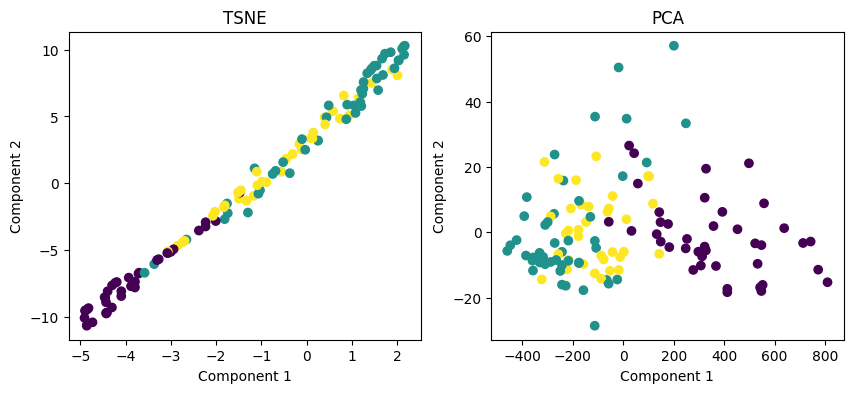

Accuracy на тестовой выборке: 1.0000


In [35]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

# 1. Понижение размерности
# Используем X_train_full, так как обучались на всех признаках
tsne = TSNE(n_components=2, random_state=42, init='pca', learning_rate="auto")
df_tsne = tsne.fit_transform(X_train_full)

pca = PCA(n_components=2, random_state=42)
df_pca = pca.fit_transform(X_train_full)

# 2. Отрисовка графиков
plt.figure(figsize=(10, 4))

# График TSNE (слева)
ax0 = plt.subplot(1, 2, 1)
ax0.set_title("TSNE")
ax0.scatter(df_tsne[:, 0], df_tsne[:, 1], c=pred_classes, cmap='viridis')
ax0.set_xlabel("Component 1")
ax0.set_ylabel("Component 2")

# График PCA (справа)
ax1 = plt.subplot(1, 2, 2)
ax1.set_title("PCA")
ax1.scatter(df_pca[:, 0], df_pca[:, 1], c=pred_classes, cmap='viridis')
ax1.set_xlabel("Component 1")
ax1.set_ylabel("Component 2")

# Обязательная команда для отображения графиков в Colab
plt.show()

# 3. Расчет Accuracy (на случай, если вы не делали это в отдельной ячейке)
model_full.eval()
with torch.no_grad():
    test_outputs = model_full(X_test_full_t)
    _, test_preds = torch.max(test_outputs, 1)
    test_preds = test_preds.cpu().numpy()

accuracy = accuracy_score(y_test_full, test_preds)
print(f"Accuracy на тестовой выборке: {accuracy:.4f}")

Сдайте работу преподавателю

В помощь

при визуализации используйте пространство
```
xx, yy = np.meshgrid(np.arange(x_min.cpu(), x_max.cpu(), h),
                     np.arange(y_min.cpu(), y_max.cpu(), h))
```

делайте предсказания в z
и стройте контуры
```
plt.contourf(xx, yy, Z.detach().cpu().numpy(), cmap=cm, alpha=.8)
```

внимательно изучите, что такое y в данном примере


ожидаемые изображения

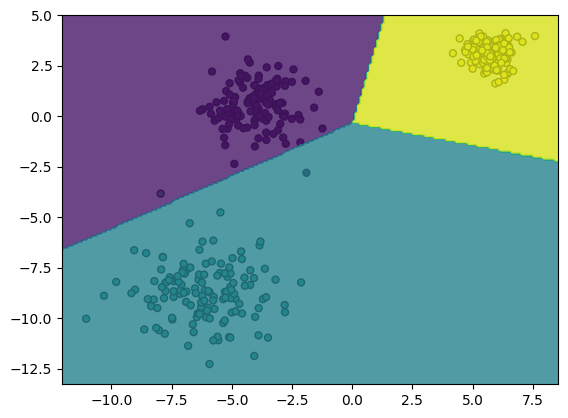

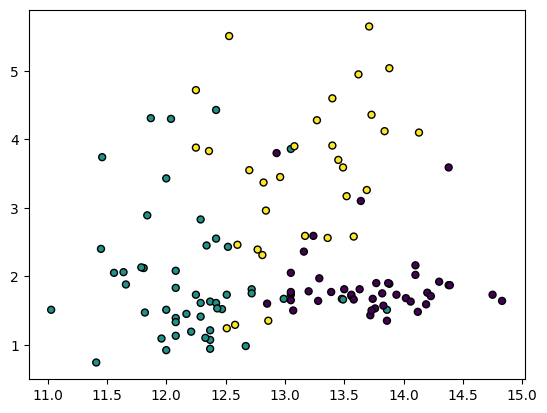

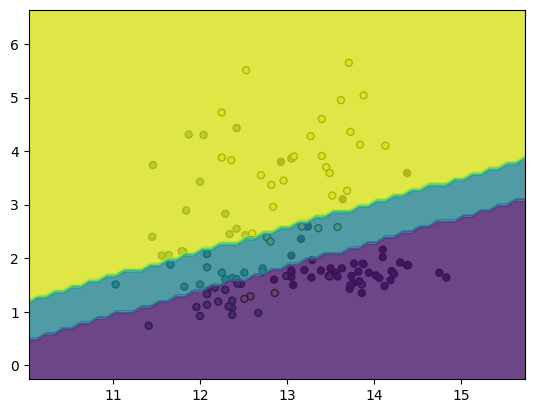

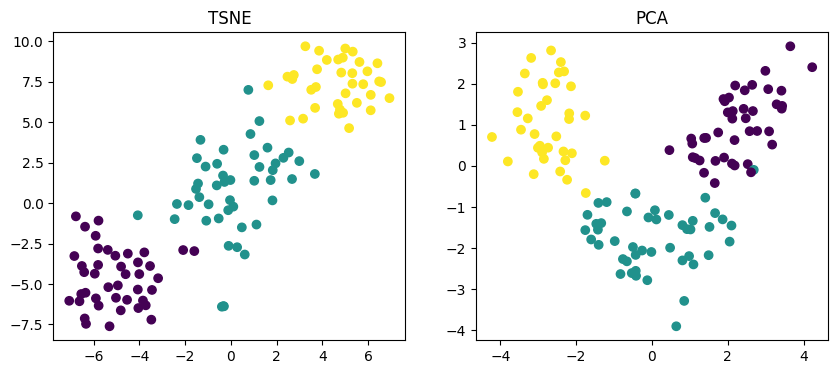

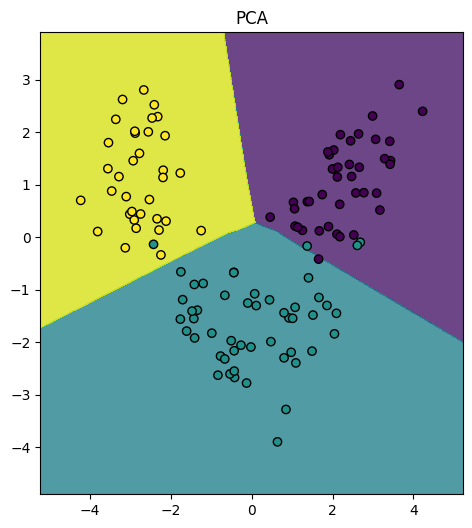